Trainable parameters: 57586
Train        0.932 ± 0.007
Val          0.433 ± 0.009
Clean test   0.359 ± 0.012
Shifted test 0.170 ± 0.006


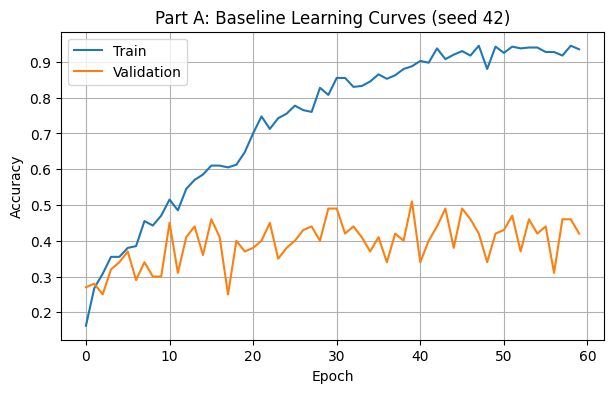

In [6]:
#A: Setup + Baseline
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

DATA_SEED = 42                 # dataset set
SEEDS = [42, 123, 456]         # 3 training runs

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
norm = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_raw = torchvision.datasets.CIFAR10('./data', train=True,  download=True)
test_raw  = torchvision.datasets.CIFAR10('./data', train=False, download=True)
CLASSES = train_raw.classes

set_seed(DATA_SEED)
labels = np.array(train_raw.targets)
train_idx, val_idx = [], []
for c in range(10):
    idx = np.random.permutation(np.where(labels == c)[0])[:50]
    train_idx += list(idx[:40]); val_idx += list(idx[40:])

def to_tensors(base, idx):
    X = torch.stack([norm(base[i][0]) for i in idx])
    y = torch.tensor([base[i][1] for i in idx])
    return X, y

X_train, y_train = to_tensors(train_raw, train_idx)
X_val,   y_val   = to_tensors(train_raw, val_idx)
X_clean, y_clean = to_tensors(test_raw, range(10000))

#Shifted test
class Corrupt:
    def __init__(self, seed): self.r = np.random.RandomState(seed)
    def __call__(self, img):
        r = self.r
        img = TF.rotate(img, r.uniform(-25, 25))
        img = TF.adjust_brightness(img, r.uniform(0.6, 1.4))
        img = TF.adjust_contrast(img, r.uniform(0.6, 1.4))
        a = np.array(img)
        x, y = r.randint(0, 17), r.randint(0, 17)
        a[y:y+16, x:x+16] = 0
        img = Image.fromarray(a)
        if r.rand() < 0.5:
            img = TF.rgb_to_grayscale(img, 3)
        return img

corrupt = Corrupt(DATA_SEED)
X_shift = torch.stack([norm(corrupt(img)) for img, _ in test_raw])
X_gray  = torch.stack([norm(TF.rgb_to_grayscale(img, 3)) for img, _ in test_raw])

mk = lambda X, y, shuf=False, bs=128: DataLoader(TensorDataset(X, y), batch_size=bs, shuffle=shuf)
train_loader = mk(X_train, y_train, shuf=True, bs=32)
val_loader, clean_loader = mk(X_val, y_val), mk(X_clean, y_clean)
shift_loader, gray_loader = mk(X_shift, y_clean), mk(X_gray, y_clean)

# Inception module
class Inception(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b1 = nn.Conv2d(c, 16, 1)
        self.b3 = nn.Sequential(nn.Conv2d(c, 16, 1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1))
        self.b5 = nn.Sequential(nn.Conv2d(c, 8, 1),  nn.ReLU(), nn.Conv2d(8, 16, 5, padding=2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), nn.Conv2d(c, 16, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class Net(nn.Module):
    def __init__(self, drop=0.3):
        super().__init__()
        self.c1, self.bn1 = nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32)
        self.inc = Inception(32)
        self.c2, self.bn2 = nn.Conv2d(80, 64, 3, padding=1), nn.BatchNorm2d(64)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(64, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.c1(x))), 2)
        x = F.max_pool2d(self.inc(x), 2)
        x = F.max_pool2d(F.relu(self.bn2(self.c2(x))), 2)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(self.drop(x))

print("Trainable parameters:", sum(p.numel() for p in Net().parameters() if p.requires_grad))

def train_epoch(model, loader, opt, crit):
    model.train(); correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); out = model(x); crit(out, y).backward(); opt.step()
        correct += (out.argmax(1) == y).sum().item(); total += len(y)
    return correct / total

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item(); total += len(y)
    return correct / total

# baseline
rows = []
for s in SEEDS:
    set_seed(s)
    model = Net().to(device)
    opt, crit = torch.optim.Adam(model.parameters(), lr=1e-3), nn.CrossEntropyLoss()
    tr, va = [], []
    for ep in range(60):
        tr.append(train_epoch(model, train_loader, opt, crit))
        va.append(evaluate(model, val_loader))
    rows.append([tr[-1], va[-1], evaluate(model, clean_loader), evaluate(model, shift_loader)])
    if s == SEEDS[0]: tr0, va0 = tr, va

rows = np.array(rows)
for name, m, sd in zip(["Train", "Val", "Clean test", "Shifted test"], rows.mean(0), rows.std(0)):
    print(f"{name:13s}{m:.3f} ± {sd:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(tr0, label="Train"); plt.plot(va0, label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Part A: Baseline Learning Curves (seed 42)")
plt.legend(); plt.grid(True); plt.show()

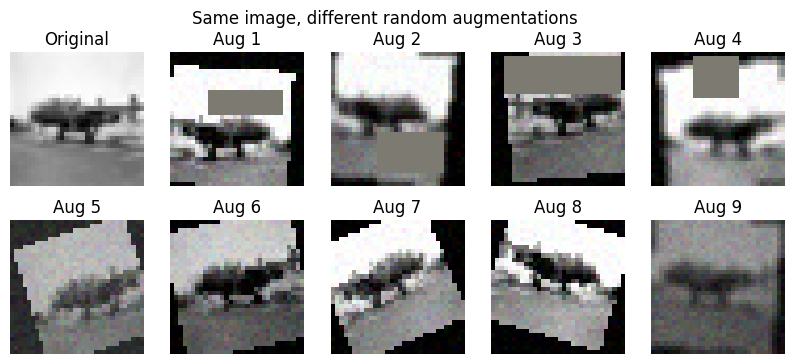

In [12]:
#Augmentation
train_pil = [train_raw[i][0] for i in train_idx]   #the 400 raw images
train_lbl = [train_raw[i][1] for i in train_idx]

class AugSet(torch.utils.data.Dataset):
    def __init__(self, tf): self.tf = tf
    def __len__(self): return len(train_pil)
    def __getitem__(self, i): return self.tf(train_pil[i]), train_lbl[i]

def make_tf(geo=False, photo=False, cutout=False):
    ops = []
    if geo:
        ops += [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.RandomRotation(25)]
    if photo:
        ops += [T.ColorJitter(0.4, 0.4, 0.4),
                T.RandomApply([T.GaussianBlur(3)], p=0.3),
                T.RandomGrayscale(p=0.25)]
    ops += [T.ToTensor()]
    if photo:
        ops += [T.Lambda(lambda x: x + 0.03 * torch.randn_like(x))]     # noise
    ops += [T.Normalize(MEAN, STD)]
    if cutout:
        ops += [T.RandomErasing(p=0.5, scale=(0.1, 0.3))]  # Cutout / occlusion
    return T.Compose(ops)

def mixup(x, y, alpha=0.4):
    lam = np.random.beta(alpha, alpha)
    perm = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

#1 image, 9 random augmentations
tf_all = make_tf(True, True, True)
fig, ax = plt.subplots(2, 5, figsize=(10, 4))
ax[0, 0].imshow(train_pil[0]); ax[0, 0].set_title("Original")
for k, a in enumerate(ax.flat[1:]):
    im = tf_all(train_pil[0]) * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    a.imshow(im.permute(1, 2, 0).clamp(0, 1)); a.set_title(f"Aug {k+1}")
for a in ax.flat: a.axis("off")
plt.suptitle("Same image, different random augmentations"); plt.show()

In [8]:
#Training with regularization
import copy

def run(geo=False, photo=False, cutout=False, use_mixup=False, ls=0.0,
        seed=42, epochs=60, patience=15, wd=5e-4, drop=0.3):
    set_seed(seed)
    loader = DataLoader(AugSet(make_tf(geo, photo, cutout)), batch_size=32, shuffle=True)
    model = Net(drop).to(device)                                            # BatchNorm + Dropout are inside Net
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=wd)   # weight decay
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)   # learning-rate schedule
    crit = nn.CrossEntropyLoss(label_smoothing=ls)                          # label smoothing
    best_val, best_state, wait = -1, None, 0
    for ep in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            if use_mixup:
                xm, ya, yb, lam = mixup(x, y)
                out = model(xm)
                loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb)
            else:
                loss = crit(model(x), y)
            loss.backward(); opt.step()
        sched.step()
        val = evaluate(model, val_loader) #early stopping
        if val > best_val:
            best_val, best_state, wait = val, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)    # go back to the best epoch
    return evaluate(model, val_loader), evaluate(model, clean_loader), evaluate(model, shift_loader), model

v, c, sh, _ = run(geo=True, photo=True, cutout=True, use_mixup=True, ls=0.1, epochs=3)
print(" val", round(v, 3), ", clean", round(c, 3), ", shifted", round(sh, 3))

 val 0.19 , clean 0.21 , shifted 0.18


In [9]:
#Ablation
import pandas as pd

configs = {
    "No augmentation":            dict(),
    "Geometric only":             dict(geo=True),
    "Photometric only":           dict(photo=True),
    "Geo+Photo+Cutout+Mixup+LS":  dict(geo=True, photo=True, cutout=True, use_mixup=True, ls=0.1),
}

results, models = {}, {}
for name, cfg in configs.items():
    r = []
    for s in SEEDS:
        v, c, sh, m = run(seed=s, **cfg)
        r.append([v, c, sh])
        if s == SEEDS[0]: models[name] = m
    results[name] = np.array(r)

best = max(results, key=lambda n: results[n][:, 0].mean())
fmt = lambda r, k: f"{r[:, k].mean():.3f} ± {r[:, k].std():.3f}"
table = pd.DataFrame({n: [fmt(r, 0), fmt(r, 1), fmt(r, 2)] for n, r in results.items()},
                     index=["Val Acc", "Clean Test", "Shifted Test"]).T
table.loc[f"Final model (= {best})"] = table.loc[best]
print(table)

base = results["No augmentation"][:, 2].mean()
print("\nShifted-test gain vs no augmentation:")
for n, r in results.items():
    print(f"  {n}: {r[:, 2].mean() - base:+.3f}")

final_model = models[best]

                                        Val Acc     Clean Test   Shifted Test
No augmentation                   0.520 ± 0.022  0.430 ± 0.012  0.186 ± 0.017
Geometric only                    0.407 ± 0.012  0.363 ± 0.003  0.192 ± 0.019
Photometric only                  0.540 ± 0.008  0.422 ± 0.006  0.189 ± 0.009
Geo+Photo+Cutout+Mixup+LS         0.400 ± 0.033  0.343 ± 0.011  0.198 ± 0.010
Final model (= Photometric only)  0.540 ± 0.008  0.422 ± 0.006  0.189 ± 0.009

Shifted-test gain vs no augmentation:
  No augmentation: +0.000
  Geometric only: +0.006
  Photometric only: +0.003
  Geo+Photo+Cutout+Mixup+LS: +0.012


In [10]:
extra = {
    "Geometric + photometric":   dict(geo=True, photo=True),
    "+ Cutout / Random Erasing": dict(geo=True, photo=True, cutout=True),
}
for name, cfg in extra.items():
    r = []
    for s in SEEDS:
        v, c, sh, m = run(seed=s, **cfg)
        r.append([v, c, sh])
        if s == SEEDS[0]: models[name] = m
    results[name] = np.array(r)

order = ["No augmentation", "Geometric only", "Photometric only",
         "Geometric + photometric", "+ Cutout / Random Erasing", "Geo+Photo+Cutout+Mixup+LS"]
best = max(order, key=lambda n: results[n][:, 0].mean())      # chosen on validation only
table = pd.DataFrame({n: [fmt(results[n], 0), fmt(results[n], 1), fmt(results[n], 2)] for n in order},
                     index=["Val Acc", "Clean Test", "Shifted Test"]).T
table.loc[f"Final model (= {best})"] = table.loc[best]
print(table)
final_model = models[best]

                                        Val Acc     Clean Test   Shifted Test
No augmentation                   0.520 ± 0.022  0.430 ± 0.012  0.186 ± 0.017
Geometric only                    0.407 ± 0.012  0.363 ± 0.003  0.192 ± 0.019
Photometric only                  0.540 ± 0.008  0.422 ± 0.006  0.189 ± 0.009
Geometric + photometric           0.443 ± 0.025  0.353 ± 0.008  0.214 ± 0.006
+ Cutout / Random Erasing         0.423 ± 0.026  0.352 ± 0.009  0.211 ± 0.002
Geo+Photo+Cutout+Mixup+LS         0.400 ± 0.033  0.343 ± 0.011  0.198 ± 0.010
Final model (= Photometric only)  0.540 ± 0.008  0.422 ± 0.006  0.189 ± 0.009


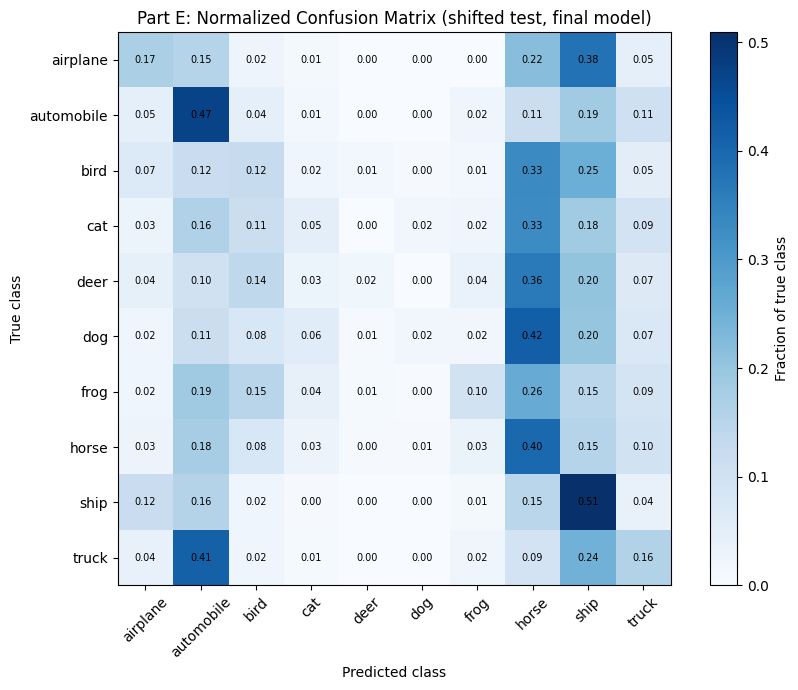

Per-class accuracy (shifted test):
  airplane    0.170
  automobile  0.471
  bird        0.125
  cat         0.050
  deer        0.018
  dog         0.017
  frog        0.097
  horse       0.396
  ship        0.509
  truck       0.161

Most confused pairs (true -> predicted):
  dog -> horse: 0.42
  truck -> automobile: 0.41
  airplane -> ship: 0.38
  deer -> horse: 0.36
  bird -> horse: 0.33


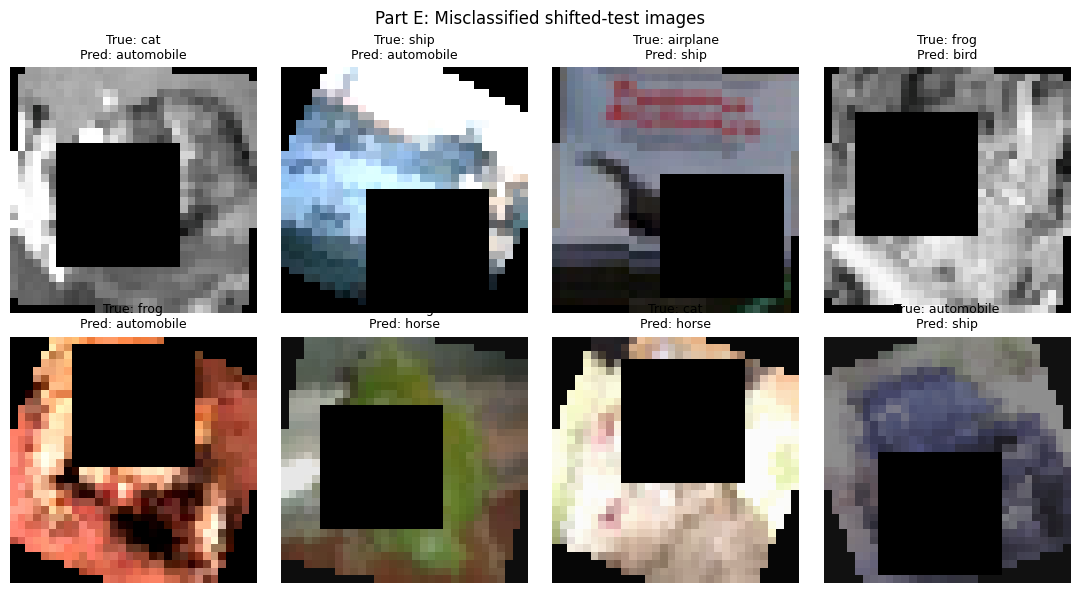


Hidden-corruption-only accuracy: 0.372 | clean accuracy: 0.414


In [11]:
# Error analysis
@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.cat([model(X[i:i+500].to(device)).argmax(1).cpu() for i in range(0, len(X), 500)])

yt = y_clean.numpy()
pr = predict(final_model, X_shift).numpy()

# 1. Normalized confusion matrix
cm = np.zeros((10, 10))
for t, p in zip(yt, pr): cm[t, p] += 1
cm = cm / cm.sum(1, keepdims=True)

plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues"); cb = plt.colorbar(); cb.set_label("Fraction of true class")
plt.xticks(range(10), CLASSES, rotation=45); plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.xlabel("Predicted class"); plt.ylabel("True class")
plt.title("Part E: Normalized Confusion Matrix (shifted test, final model)")
plt.tight_layout(); plt.show()

print("Per-class accuracy (shifted test):")
for i, c in enumerate(CLASSES): print(f"  {c:11s} {cm[i, i]:.3f}")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nMost confused pairs (true -> predicted):")
for idx in np.argsort(-off.ravel())[:5]:
    a, b = divmod(idx, 10); print(f"  {CLASSES[a]} -> {CLASSES[b]}: {off[a, b]:.2f}")

wrong = np.where(pr != yt)[0][:8]
fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for a, i in zip(ax.flat, wrong):
    im = X_shift[i] * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    a.imshow(im.permute(1, 2, 0).clamp(0, 1))
    a.set_title(f"True: {CLASSES[yt[i]]}\nPred: {CLASSES[pr[i]]}", fontsize=9); a.axis("off")
plt.suptitle("Part E: Misclassified shifted-test images"); plt.tight_layout(); plt.show()

print(f"\nHidden-corruption-only accuracy: {evaluate(final_model, gray_loader):.3f}"
      f" | clean accuracy: {evaluate(final_model, clean_loader):.3f}")